# Heuers statistical Football model

The following implementation aims to recreate the Football model of Prof. Dr. Andreas Heuer.

In [88]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
SEED = 1893

In [89]:
def plot_per_season_per_country(df, y, fit_reg=True):
    seasons = [14, 15, 16, 17, 18]
    sns.lmplot(x="season", y=y,
               hue="country", data=df, ci=None, fit_reg=fit_reg)
    plt.xticks(seasons, ["14-15", "15-16", "16-17", "17-18", "18-19"])
    sumed_df = pd.DataFrame()
    sumed_df["season"] = seasons
    total = []
    for season in seasons:
        total.append(np.sum(df.groupby(["season"]).get_group(
            season)[y]) / NUM_OF_COUNTRIES)
    sumed_df[y] = total
    sns.lmplot(x="season", y=y,
               data=sumed_df, ci=None, fit_reg=fit_reg)
    plt.xticks(seasons, ["14-15", "15-16", "16-17", "17-18", "18-19"])
    plt.show()


## Step 1 - Homefieldadvantage

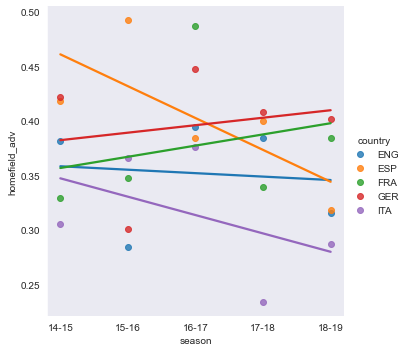

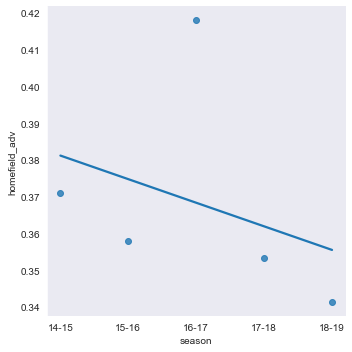

In [90]:
df_homefield = pd.read_csv('data/homefield_adv.csv', sep=';')

plot_per_season_per_country(df_homefield, y="homefield_adv")

Homefield advantage tends to have high variance, a clear trend per country or season is not visible.
Therefor homefield advantage will be modeled as an constant of the average of hometeamgoals - awayteamgoals

In [91]:
homefield_adv = np.sum(df_homefield["homefield_adv"]) / NUM_OF_SEASONS
print("Homefield advantage:", homefield_adv)

Homefield advantage: 0.36837358101135187


## Step 2 - Goalamount per match

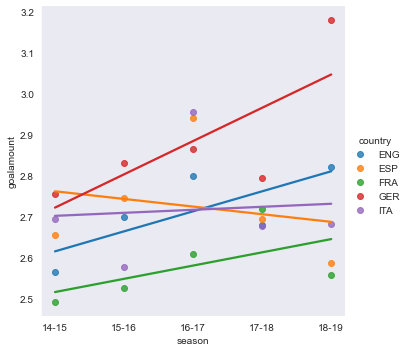

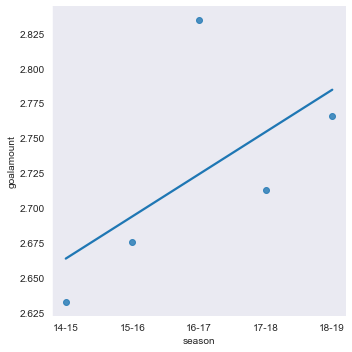

In [92]:
df_goalamount = pd.read_csv('data/goalamount.csv', sep=';')
plot_per_season_per_country(df_goalamount, "goalamount")

there are higher scored countrys as well as lower scoring ones
for now the goalamount will be modeled as a constant

In [93]:
goalamount = np.sum(df_goalamount["goalamount"]) / NUM_OF_SEASONS
goalamount

2.724046095631235

## Step 3: Teamstrength and expected goaldifference

In [ ]:
# in der ersten saison werden alle als aufsteiger betrachtet
